In [ ]:
import tensorflow
from tensorflow import keras

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input,Dense
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [ ]:
url = "https://storage.googleapis.com/download.tensorflow.org/data/ecg.csv"

df = pd.read_csv(url,header=None)

In [ ]:
df.head()

,0,1,2,3,4,5,6,7,8,9,...,131,132,133,134,135,136,137,138,139,140
0,-0.112522,-2.827204,-3.773897,-4.349751,-4.376041,-3.474986,-2.181408,-1.818286,-1.250522,-0.477492,...,0.792168,0.933541,0.796958,0.578621,0.257740,0.228077,0.123431,0.925286,0.193137,1.0
1,-1.100878,-3.996840,-4.285843,-4.506579,-4.022377,-3.234368,-1.566126,-0.992258,-0.754680,0.042321,...,0.538356,0.656881,0.787490,0.724046,0.555784,0.476333,0.773820,1.119621,-1.436250,1.0
2,-0.567088,-2.593450,-3.874230,-4.584095,-4.187449,-3.151462,-1.742940,-1.490659,-1.183580,-0.394229,...,0.886073,0.531452,0.311377,-0.021919,-0.713683,-0.532197,0.321097,0.904227,-0.421797,1.0
3,0.490473,-1.914407,-3.616364,-4.318823,-4.268016,-3.881110,-2.993280,-1.671131,-1.333884,-0.965629,...,0.350816,0.499111,0.600345,0.842069,0.952074,0.990133,1.086798,1.403011,-0.383564,1.0
4,0.800232,-0.874252,-2.384761,-3.973292,-4.338224,-3.802422,-2.534510,-1.783423,-1.594450,-0.753199,...,1.148884,0.958434,1.059025,1.371682,1.277392,0.960304,0.971020,1.614392,1.421456,1.0


In [ ]:
df.shape

(4998, 141)

In [ ]:
df = df.drop(140,axis=1)


In [ ]:
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [ ]:
ss = StandardScaler()
df  =ss.fit_transform(df)

In [ ]:
xtrain,xtest = train_test_split(df,train_size=0.8)

In [ ]:
xtrain.shape[1]

140

In [ ]:
encoder = Sequential([
    Input(shape=(xtrain.shape[1],)),
    Dense(64,activation='relu'),
    Dense(32,activation='relu'),
    Dense(16,activation='relu'),
    Dense(8,activation='relu')
])

decoder = Sequential([
    Input(shape=(8,)),
    Dense(16,activation='relu'),
    Dense(32,activation='relu'),
    Dense(64,activation='relu'),
    Dense(xtrain.shape[1],activation='linear')
])

model = Sequential([encoder,decoder])

In [ ]:
model.compile(optimizer='adam',loss='mse',metrics=['accuracy'])

In [ ]:
model.fit(xtrain,xtrain,epochs=10,validation_data=(xtest,xtest))


Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.0230 - loss: 0.7604 - val_accuracy: 0.0250 - val_loss: 0.4696
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.0383 - loss: 0.4105 - val_accuracy: 0.0650 - val_loss: 0.3008
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.0830 - loss: 0.3197 - val_accuracy: 0.1240 - val_loss: 0.2636
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1058 - loss: 0.2940 - val_accuracy: 0.0900 - val_loss: 0.2478
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1153 - loss: 0.2773 - val_accuracy: 0.1210 - val_loss: 0.2230
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1243 - loss: 0.2556 - val_accuracy: 0.1370 - val_loss: 0.2075
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1288 - loss: 0.2418 - val_accuracy: 0.1480 - val_loss: 0.1966
Epoch 8/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1336 - loss: 0.2305 - val_accuracy: 0.

In [ ]:
model.evaluate(xtest,xtest)

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1570 - loss: 0.1811


[0.1811358630657196, 0.15700000524520874]

In [ ]:
pred=model.predict(xtest)

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


In [ ]:
mse= np.mean(np.power((xtest-pred),2),axis=1)

In [ ]:
ts = np.percentile(mse,95)

In [ ]:
anom = mse>ts

In [ ]:
cnt = np.sum(anom)
cnt

np.int64(50)

<Axes: >

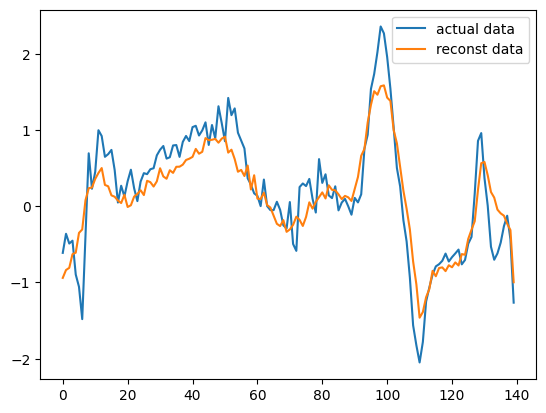

In [ ]:
sns.lineplot(xtest[1],label='actual data')
sns.lineplot(pred[1],label='reconst data')
